# Day 2 · Linear Regression from scratch (NumPy)
Manual gradient-descent loop, MSE tracking, Matplotlib loss curve.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
NUM = ["Rainfall_mm", "Temperature_Celsius", "Fertilizer_Used", "Irrigation_Used", "Days_to_Harvest"]
X_all = df[NUM].astype(float).to_numpy()
y_all = df["Yield_tons_per_hectare"].to_numpy()
rng = np.random.default_rng(42)
idx = rng.permutation(len(df)); cut = int(0.8 * len(df))
tr, te = idx[:cut], idx[cut:]
mu, sd = X_all[tr].mean(0), X_all[tr].std(0)
Xtr = np.c_[np.ones(len(tr)), (X_all[tr]-mu)/sd]; ytr = y_all[tr]
Xte = np.c_[np.ones(len(te)), (X_all[te]-mu)/sd]; yte = y_all[te]

Features are standardised with **train** statistics only. Column 0 is the bias term.

In [3]:
def mse(X, y, w): return np.mean((X @ w - y) ** 2)

w = np.zeros(Xtr.shape[1])
lr, epochs = 0.02, 300
train_losses, test_losses = [], []
for epoch in range(epochs):
    grad = (2 / len(ytr)) * Xtr.T @ (Xtr @ w - ytr)     # dMSE/dw
    w -= lr * grad
    train_losses.append(mse(Xtr, ytr, w)); test_losses.append(mse(Xte, yte, w))
    if epoch % 50 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:3d}  train MSE {train_losses[-1]:.4f}  test MSE {test_losses[-1]:.4f}")

epoch   0  train MSE 22.5949  test MSE 22.5961


epoch  50  train MSE 0.6277  test MSE 0.6263


epoch 100  train MSE 0.2571  test MSE 0.2559


epoch 150  train MSE 0.2508  test MSE 0.2497


epoch 200  train MSE 0.2507  test MSE 0.2496


epoch 250  train MSE 0.2507  test MSE 0.2496


epoch 299  train MSE 0.2507  test MSE 0.2496


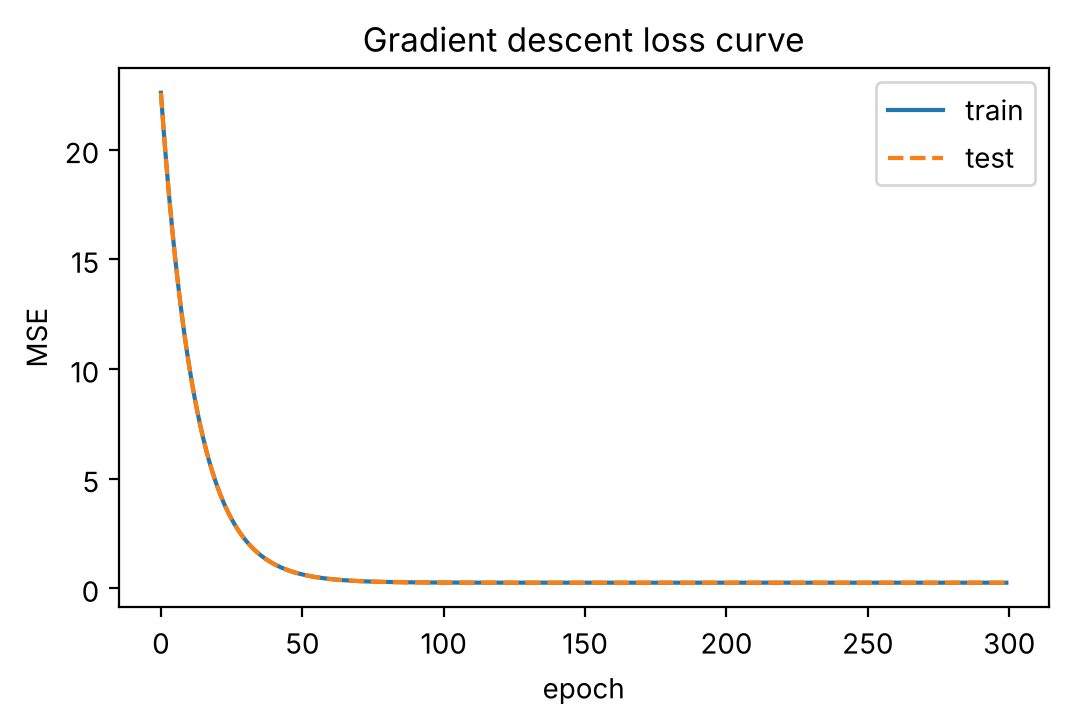

GD weights     : [4.6495e+00 1.2980e+00 1.4400e-01 7.4990e-01 5.9960e-01 7.0000e-04]
Closed-form    : [4.6495e+00 1.2981e+00 1.4400e-01 7.4990e-01 5.9960e-01 7.0000e-04]
test R^2: 0.9134
features: ['bias', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Days_to_Harvest']


In [4]:
plt.figure(figsize=(6, 3.5))
plt.plot(train_losses, label="train"); plt.plot(test_losses, "--", label="test")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Gradient descent loss curve"); plt.legend(); plt.show()

w_ls = np.linalg.lstsq(Xtr, ytr, rcond=None)[0]
print("GD weights     :", np.round(w, 4))
print("Closed-form    :", np.round(w_ls, 4))
ss_res = ((Xte @ w - yte) ** 2).sum(); ss_tot = ((yte - yte.mean()) ** 2).sum()
print("test R^2:", round(1 - ss_res / ss_tot, 4))
print("features:", ["bias"] + NUM)
np.save("day2_weights.npy", w)